In [16]:
!python -m pip install streamlit pandas scikit-learn matplotlib wordcloud


[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [17]:
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from wordcloud import WordCloud
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             confusion_matrix, classification_report)

%matplotlib inline

In [19]:
df = pd.read_csv(r"C:\Analisis_sentimen_menggunakan_Neural_Network\tweet_data.csv")
print("Jumlah data :", len(df))
print("Kolom       :", list(df.columns))
df.head()

Jumlah data : 1200
Kolom       : ['created_at', 'username', 'full_text']


,created_at,username,full_text
0,2026-07-15 10:25:27,lensa_pontianak219,"Relawan sigap membantu evakuasi di Palu, situa..."
1,2026-07-16 01:35:00,lensa_tangguh366,Sosialisasi mitigasi bencana akan diadakan di ...
2,2026-07-16 02:45:06,sahabat_siaga2,Kondisi Lombok mulai pulih berkat gotong royon...
3,2026-07-16 03:32:51,sahabat_siaga618,BREAKING: Simulasi evakuasi gempa di Sintang b...
4,2026-07-16 06:39:53,info_lestari430,Tim BPBD Bandung memetakan wilayah rawan benca...


In [20]:
def bersihkan_teks(teks):
    teks = str(teks)
    teks = re.sub(r"https?://\S+|www\.\S+", " ", teks)   # URL
    teks = re.sub(r"@\w+", " ", teks)                     # mention
    teks = re.sub(r"#\w+", " ", teks)                     # hashtag
    teks = re.sub(r"\brt\b", " ", teks, flags=re.I)       # sisa 'RT'
    teks = re.sub(r"\d+", " ", teks)                      # angka
    teks = re.sub(r"[^a-zA-Z\s]", " ", teks)              # simbol & tanda baca
    teks = teks.lower()                                   # case folding
    teks = re.sub(r"\s+", " ", teks).strip()              # spasi berlebih
    return teks

df = df.dropna(subset=["full_text"]).drop_duplicates(subset=["full_text"])
df["clean_text"] = df["full_text"].apply(bersihkan_teks)
df = df[df["clean_text"] != ""].reset_index(drop=True)
df[["full_text", "clean_text"]].head()

,full_text,clean_text
0,"Relawan sigap membantu evakuasi di Palu, situa...",relawan sigap membantu evakuasi di palu situas...
1,Sosialisasi mitigasi bencana akan diadakan di ...,sosialisasi mitigasi bencana akan diadakan di ...
2,Kondisi Lombok mulai pulih berkat gotong royon...,kondisi lombok mulai pulih berkat gotong royon...
3,BREAKING: Simulasi evakuasi gempa di Sintang b...,breaking simulasi evakuasi gempa di sintang be...
4,Tim BPBD Bandung memetakan wilayah rawan benca...,tim bpbd bandung memetakan wilayah rawan benca...


In [21]:
# NORMALISASI KATA
# Kamus ini dapat ditambah sesuai istilah tidak baku yang ditemukan pada dataset.
KAMUS_NORMALISASI = {
    "gak": "tidak",
    "ga": "tidak",
    "nggak": "tidak",
    "enggak": "tidak",
    "tdk": "tidak",
    "yg": "yang",
    "dgn": "dengan",
    "utk": "untuk",
    "krn": "karena",
    "karna": "karena",
    "jd": "jadi",
    "dr": "dari",
    "dlm": "dalam",
    "sdh": "sudah",
    "udh": "sudah",
    "blm": "belum",
    "bgt": "banget",
    "aja": "saja",
    "org": "orang",
    "warga2": "warga",
    "bansos": "bantuan sosial",
    "karhutla": "kebakaran hutan dan lahan",
    "evakuasi": "evakuasi",
    "bpbd": "bpbd",
}

def normalisasi_teks(teks):
    teks = str(teks)
    kata_hasil = []
    for kata in teks.split():
        kata_hasil.append(KAMUS_NORMALISASI.get(kata, kata))
    return " ".join(kata_hasil)

# Membuat kolom hasil normalisasi dari teks yang sudah dibersihkan.
df["normalized_text"] = df["clean_text"].apply(normalisasi_teks)

display(df[["full_text", "clean_text", "normalized_text"]].head(10))

# Simpan hasil normalisasi agar dapat digunakan kembali.
df[["full_text", "clean_text", "normalized_text"]].to_csv(
    "data_normalisasi_mitigasi_bencana.csv",
    index=False,
    encoding="utf-8-sig"
)
print("Data normalisasi berhasil disimpan: data_normalisasi_mitigasi_bencana.csv")


,full_text,clean_text,normalized_text
0,"Relawan sigap membantu evakuasi di Palu, situa...",relawan sigap membantu evakuasi di palu situas...,relawan sigap membantu evakuasi di palu situas...
1,Sosialisasi mitigasi bencana akan diadakan di ...,sosialisasi mitigasi bencana akan diadakan di ...,sosialisasi mitigasi bencana akan diadakan di ...
2,Kondisi Lombok mulai pulih berkat gotong royon...,kondisi lombok mulai pulih berkat gotong royon...,kondisi lombok mulai pulih berkat gotong royon...
3,BREAKING: Simulasi evakuasi gempa di Sintang b...,breaking simulasi evakuasi gempa di sintang be...,breaking simulasi evakuasi gempa di sintang be...
4,Tim BPBD Bandung memetakan wilayah rawan benca...,tim bpbd bandung memetakan wilayah rawan benca...,tim bpbd bandung memetakan wilayah rawan benca...
5,Jalur evakuasi di Semarang sudah jelas dan ama...,jalur evakuasi di semarang sudah jelas dan ama...,jalur evakuasi di semarang sudah jelas dan ama...
6,BREAKING: Kondisi Cianjur mulai pulih berkat g...,breaking kondisi cianjur mulai pulih berkat go...,breaking kondisi cianjur mulai pulih berkat go...
7,RT Pemkot Pontianak membahas anggaran penanggu...,pemkot pontianak membahas anggaran penanggulan...,pemkot pontianak membahas anggaran penanggulan...
8,"Longsor di Manado menelan korban, jalur evakua...",longsor di manado menelan korban jalur evakuas...,longsor di manado menelan korban jalur evakuas...
9,Sistem peringatan dini tsunami Semarang bekerj...,sistem peringatan dini tsunami semarang bekerj...,sistem peringatan dini tsunami semarang bekerj...


Data normalisasi berhasil disimpan: data_normalisasi_mitigasi_bencana.csv


In [32]:
KATA_POSITIF = [
    "siap", "tanggap", "sigap", "aman", "lega", "selamat", "pulih", "berhasil",
    "terkendali", "efektif", "bagus", "lancar", "bantuan", "terima kasih",
    "tertata", "terlayani", "syukur", "baik",
]

KATA_NEGATIF = [
    "banjir", "parah", "rusak", "kerusakan", "bahaya", "berbahaya", "membahayakan",
    "korban", "longsor", "lambat", "kecewa", "minim", "terlambat", "gagal",
    "resah", "panik", "jebol", "buruk", "lalai", "memprihatinkan", "kekurangan",
    "terendam", "tertutup", "rawan",
]

def hitung(teks_bersih, daftar):
    return sum(
        len(re.findall(r"\b" + re.escape(k) + r"\b", teks_bersih))
        for k in daftar
    )

def beri_label(teks_bersih):
    pos = hitung(teks_bersih, KATA_POSITIF)
    neg = hitung(teks_bersih, KATA_NEGATIF)

    if pos > neg:
        return "positif"
    elif neg > pos:
        return "negatif"
    else:
        return "netral"

# Memberikan label berdasarkan teks yang sudah dinormalisasi
df["sentimen"] = df["normalized_text"].apply(beri_label)

# Menampilkan hasil seperti tabel yang diinginkan
display(df[["clean_text", "sentimen"]].head(10))

# Menyimpan seluruh data, termasuk hasil normalisasi
df.to_csv(
    "dataset_mitigasi_bencana_normalisasi_dan_label.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Dataset berhasil disimpan!")

,clean_text,sentimen
0,relawan sigap membantu evakuasi di palu situas...,positif
1,sosialisasi mitigasi bencana akan diadakan di ...,netral
2,kondisi lombok mulai pulih berkat gotong royon...,positif
3,breaking simulasi evakuasi gempa di sintang be...,positif
4,tim bpbd bandung memetakan wilayah rawan benca...,negatif
5,jalur evakuasi di semarang sudah jelas dan ama...,positif
6,breaking kondisi cianjur mulai pulih berkat go...,positif
7,pemkot pontianak membahas anggaran penanggulan...,netral
8,longsor di manado menelan korban jalur evakuas...,negatif
9,sistem peringatan dini tsunami semarang bekerj...,positif


Dataset berhasil disimpan!


sentimen
positif    366
netral     366
negatif    468
Name: count, dtype: int64


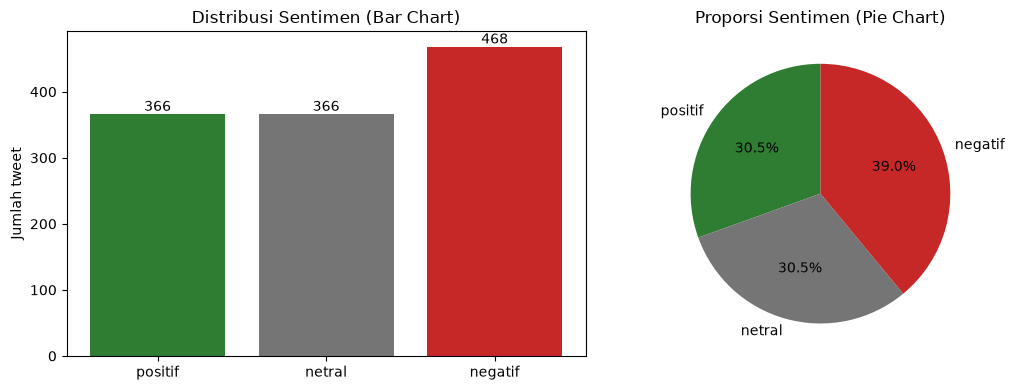

In [33]:
LABELS = ["positif", "netral", "negatif"]
WARNA = {"positif": "#2e7d32", "netral": "#757575", "negatif": "#c62828"}

dist = df["sentimen"].value_counts().reindex(LABELS).fillna(0).astype(int)
print(dist)

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

bars = axes[0].bar(dist.index, dist.values, color=[WARNA[l] for l in dist.index])
axes[0].bar_label(bars)
axes[0].set_title("Distribusi Sentimen (Bar Chart)")
axes[0].set_ylabel("Jumlah tweet")

axes[1].pie(dist.values, labels=dist.index, autopct="%1.1f%%", startangle=90,
            colors=[WARNA[l] for l in dist.index])
axes[1].set_title("Proporsi Sentimen (Pie Chart)")

plt.tight_layout()
plt.show()

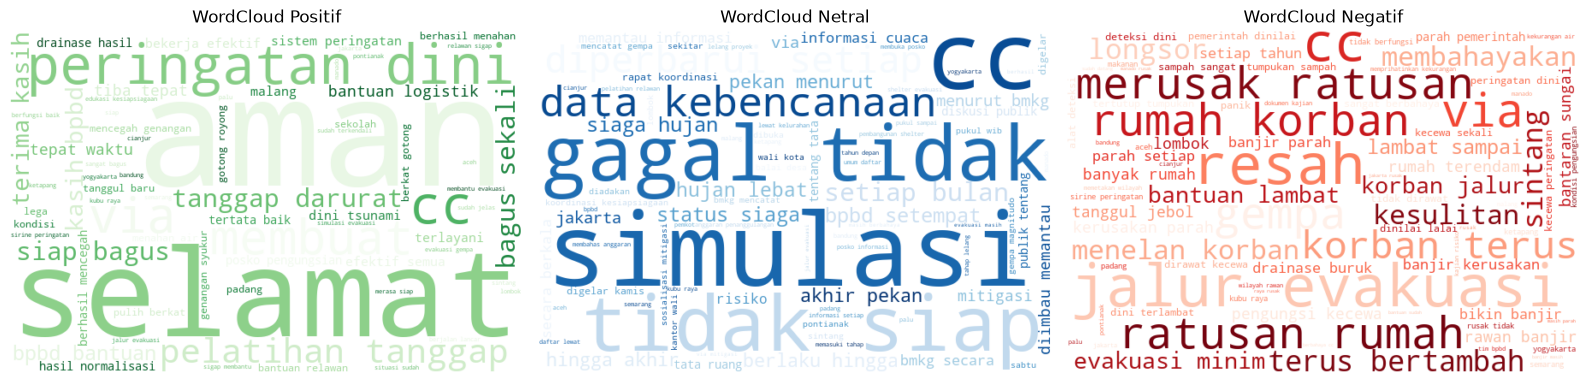

In [34]:
STOPWORDS = {
    "yang", "di", "dan", "ini", "itu", "ada", "untuk", "dengan", "dari", "pada",
    "adalah", "bahwa", "hari", "ke", "oleh", "dapat", "mulai", "menjadi", "makin",
    "akan", "bagi", "para", "juga", "tapi", "namun", "update", "breaking", "info",
    "lapor", "warga", "bencana",
}
CMAP = {"positif": "Greens", "netral": "Blues", "negatif": "Reds"}

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
for ax, lab in zip(axes, LABELS):
    teks_kelas = " ".join(df.loc[df["sentimen"] == lab, "normalized_text"])
    ax.set_title(f"WordCloud {lab.capitalize()}")
    ax.axis("off")
    if not teks_kelas.strip():
        continue
    wc = WordCloud(width=600, height=400, background_color="white",
                   colormap=CMAP[lab], stopwords=STOPWORDS,
                   random_state=1).generate(teks_kelas)
    ax.imshow(wc, interpolation="bilinear")
plt.tight_layout()
plt.show()

In [35]:
X_train, X_test, y_train, y_test = train_test_split(
    df["normalized_text"], df["sentimen"],
    test_size=0.2, random_state=42, stratify=df["sentimen"]
)
print("Data latih:", len(X_train), "| Data uji:", len(X_test))

tfidf = TfidfVectorizer(max_features=5000, ngram_range=(1, 2))
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf = tfidf.transform(X_test)

mlp = MLPClassifier(
    hidden_layer_sizes=(100,),
    activation="relu",
    solver="adam",
    max_iter=300,
    random_state=42,
)
mlp.fit(X_train_tfidf, y_train)
y_pred = mlp.predict(X_test_tfidf)
print("Pelatihan selesai. Iterasi:", mlp.n_iter_)

Data latih: 960 | Data uji: 240
Pelatihan selesai. Iterasi: 70


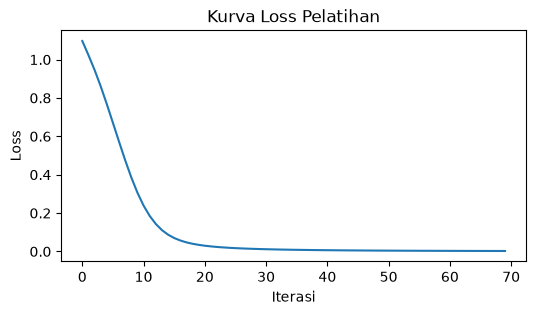

In [36]:
plt.figure(figsize=(6, 3))
plt.plot(mlp.loss_curve_)
plt.title("Kurva Loss Pelatihan")
plt.xlabel("Iterasi")
plt.ylabel("Loss")
plt.show()

In [37]:
kelas = [l for l in LABELS if l in set(y_test)]

acc = accuracy_score(y_test, y_pred)
prec, rec, f1, sup = precision_recall_fscore_support(
    y_test, y_pred, labels=kelas, zero_division=0)
p_m, r_m, f_m, _ = precision_recall_fscore_support(
    y_test, y_pred, average="macro", zero_division=0)

print(f"Akurasi          : {acc:.4f}")
print(f"Presisi (macro)  : {p_m:.4f}")
print(f"Recall (macro)   : {r_m:.4f}")
print(f"F1-Score (macro) : {f_m:.4f}\n")

tabel = pd.DataFrame({"Presisi": prec, "Recall": rec, "F1-Score": f1, "Support": sup},
                     index=kelas)
display(tabel.round(4))

print(classification_report(y_test, y_pred, labels=kelas, zero_division=0))

Akurasi          : 1.0000
Presisi (macro)  : 1.0000
Recall (macro)   : 1.0000
F1-Score (macro) : 1.0000



,Presisi,Recall,F1-Score,Support
positif,1.0,1.0,1.0,73
netral,1.0,1.0,1.0,73
negatif,1.0,1.0,1.0,94


              precision    recall  f1-score   support

     positif       1.00      1.00      1.00        73
      netral       1.00      1.00      1.00        73
     negatif       1.00      1.00      1.00        94

    accuracy                           1.00       240
   macro avg       1.00      1.00      1.00       240
weighted avg       1.00      1.00      1.00       240



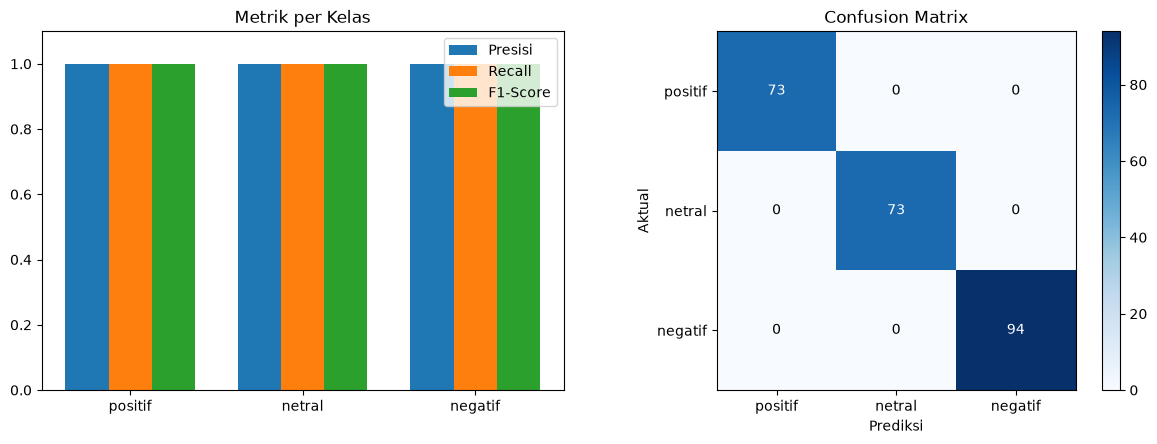

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Grafik metrik per kelas
x = np.arange(len(kelas)); w = 0.25
axes[0].bar(x - w, prec, w, label="Presisi")
axes[0].bar(x,     rec,  w, label="Recall")
axes[0].bar(x + w, f1,   w, label="F1-Score")
axes[0].set_xticks(x); axes[0].set_xticklabels(kelas)
axes[0].set_ylim(0, 1.1)
axes[0].set_title("Metrik per Kelas")
axes[0].legend()

# Confusion matrix
cm = confusion_matrix(y_test, y_pred, labels=kelas)
im = axes[1].imshow(cm, cmap="Blues")
axes[1].set_xticks(range(len(kelas))); axes[1].set_yticks(range(len(kelas)))
axes[1].set_xticklabels(kelas); axes[1].set_yticklabels(kelas)
axes[1].set_xlabel("Prediksi"); axes[1].set_ylabel("Aktual")
axes[1].set_title("Confusion Matrix")
for i in range(len(kelas)):
    for j in range(len(kelas)):
        axes[1].text(j, i, cm[i, j], ha="center", va="center",
                     color="white" if cm[i, j] > cm.max() / 2 else "black")
fig.colorbar(im, ax=axes[1])

plt.tight_layout()
plt.show()

In [39]:
EMOJI = {"positif": "😊", "netral": "😐", "negatif": "😠"}

def prediksi_sentimen(teks):
    bersih = bersihkan_teks(teks)
    if not bersih:
        print("Teks kosong setelah dibersihkan.")
        return
    vec = tfidf.transform([bersih])
    hasil = mlp.predict(vec)[0]
    proba = mlp.predict_proba(vec)[0]

    print("Teks asli        :", teks)
    print("Setelah cleansing:", bersih)
    print(f"\nHasil prediksi : {EMOJI[hasil]} {hasil.upper()}\n")
    for c, p in sorted(zip(mlp.classes_, proba), key=lambda t: -t[1]):
        print(f"  {EMOJI[c]} {c:<8} {p:.2%}")

teks_baru = "Simulasi evakuasi gempa berjalan lancar, warga siap dan aman"
prediksi_sentimen(teks_baru)

Teks asli        : Simulasi evakuasi gempa berjalan lancar, warga siap dan aman
Setelah cleansing: simulasi evakuasi gempa berjalan lancar warga siap dan aman

Hasil prediksi : 😊 POSITIF

  😊 positif  99.67%
  😠 negatif  0.16%
  😐 netral   0.16%


In [40]:
# Coba beberapa contoh sekaligus
contoh = [
    "Banjir makin parah, peringatan dini terlambat dan warga resah",
    "BPBD membuka posko informasi setiap hari pukul 08.00",
    "Relawan sigap membantu evakuasi, situasi sudah terkendali",
]
for t in contoh:
    prediksi_sentimen(t)
    print("-" * 50)

Teks asli        : Banjir makin parah, peringatan dini terlambat dan warga resah
Setelah cleansing: banjir makin parah peringatan dini terlambat dan warga resah

Hasil prediksi : 😠 NEGATIF

  😠 negatif  99.50%
  😊 positif  0.26%
  😐 netral   0.24%
--------------------------------------------------
Teks asli        : BPBD membuka posko informasi setiap hari pukul 08.00
Setelah cleansing: bpbd membuka posko informasi setiap hari pukul

Hasil prediksi : 😐 NETRAL

  😐 netral   99.59%
  😊 positif  0.21%
  😠 negatif  0.20%
--------------------------------------------------
Teks asli        : Relawan sigap membantu evakuasi, situasi sudah terkendali
Setelah cleansing: relawan sigap membantu evakuasi situasi sudah terkendali

Hasil prediksi : 😊 POSITIF

  😊 positif  99.55%
  😠 negatif  0.29%
  😐 netral   0.16%
--------------------------------------------------
